# ĐỐI CHỨNG BỔ SUNG Ridge Regression

## TN01. Cấu hình A — Time

Mục tiêu là đo khả năng dự đoán lưu lượng từ thời gian và thông tin
ngày lễ, làm mốc so sánh khi bổ sung thời tiết.

Đầu vào gồm `hour, day_of_week, month, is_weekend, is_holiday và các cột
mã hóa tên sự kiện`. Hour, day_of_week và month được one-hot trong pipeline
để Ridge học hệ số riêng cho từng giờ, thứ và tháng.

Dùng Ridge với alpha=1.0 để chạy thực nghiệm ban đầu. Huấn luyện trên
train và đánh giá trên validation bằng MAE, RMSE và R².

### Đọc dữ liệu và kiểm tra mốc chia

In [1]:
from pathlib import Path

import pandas as pd
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Tìm thư mục dự án từ thư mục hiện tại và các thư mục cha.
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "data" / "processed" / "train.csv").is_file():
        project_dir = candidate
        break
else:
    raise FileNotFoundError(
        "Không tìm thấy data/processed/train.csv. "
        "Hãy chạy notebook từ bên trong thư mục dự án."
    )

processed_dir = project_dir / "data" / "processed"

if not (processed_dir / "train.csv").is_file():
    raise FileNotFoundError(
        "Hãy chạy notebook từ thư mục metro_interstate_traffic_volume "
        "hoặc thư mục notebooks của dự án."
    )

train = pd.read_csv(
    processed_dir / "train.csv",
    parse_dates=["date_time"],
    float_precision="round_trip",
)
validation = pd.read_csv(
    processed_dir / "validation.csv",
    parse_dates=["date_time"],
    float_precision="round_trip",
)

# Kiểm tra dữ liệu đi theo thời gian và hai tập tách biệt.
assert train.columns.equals(validation.columns)
assert train["date_time"].is_unique
assert validation["date_time"].is_unique
assert train["date_time"].is_monotonic_increasing
assert validation["date_time"].is_monotonic_increasing
assert train["date_time"].max() < validation["date_time"].min()

print("Phiên bản scikit-learn:", sklearn.__version__)
display(pd.DataFrame([
    {
        "tap": name,
        "so_dong": len(part),
        "tu_gio": part["date_time"].min(),
        "den_gio": part["date_time"].max(),
    }
    for name, part in [
        ("train", train),
        ("validation", validation),
    ]
]))

Phiên bản scikit-learn: 1.7.2


,tap,so_dong,tu_gio,den_gio
0,train,28402,2012-10-02 09:00:00,2017-05-10 04:00:00
1,validation,6086,2017-05-10 05:00:00,2018-01-19 14:00:00


### Chọn đúng đặc trưng của cấu hình A

In [2]:
# Ba biến lịch được xem như các nhóm phân loại.
calendar_columns = ["hour", "day_of_week", "month"]

# Các cột này đã có dạng 0/1 từ pipeline chuẩn bị dữ liệu.
holiday_columns = [
    column for column in train.columns
    if column.startswith("holiday_")
]
binary_columns = ["is_weekend", "is_holiday"] + holiday_columns

features_A = calendar_columns + binary_columns

assert "traffic_volume" not in features_A
assert "date_time" not in features_A
assert not any(column.startswith("weather_") for column in features_A)
assert train[features_A + ["traffic_volume"]].notna().all().all()
assert validation[features_A + ["traffic_volume"]].notna().all().all()

X_train_A = train[features_A]
y_train = train["traffic_volume"]

X_validation_A = validation[features_A]
y_validation = validation["traffic_volume"]

print("Số cột đầu vào trước one-hot biến lịch:", len(features_A))
print("Danh sách đầu vào:")
print(features_A)

Số cột đầu vào trước one-hot biến lịch: 17
Danh sách đầu vào:
['hour', 'day_of_week', 'month', 'is_weekend', 'is_holiday', 'holiday_Christmas Day', 'holiday_Columbus Day', 'holiday_Independence Day', 'holiday_Labor Day', 'holiday_Martin Luther King Jr Day', 'holiday_Memorial Day', 'holiday_New Years Day', 'holiday_State Fair', 'holiday_Thanksgiving Day', 'holiday_Veterans Day', 'holiday_Washingtons Birthday', 'holiday_unknown']


### Tạo pipeline và huấn luyện Ridge

In [3]:
# Encoder được đặt trong pipeline để chỉ fit từ train.
preprocessor_A = ColumnTransformer(
    transformers=[
        (
            "calendar",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
            calendar_columns,
        ),
        (
            "binary",
            "passthrough",
            binary_columns,
        ),
    ],
    remainder="drop",
)

ridge_A = Pipeline([
    ("preprocessing", preprocessor_A),
    ("model", Ridge(alpha=1.0, solver="svd")),
])

# Học encoder và hệ số Ridge chỉ trên train.
ridge_A.fit(X_train_A, y_train)

# Dự đoán validation bằng pipeline đã học.
prediction_A = ridge_A.predict(X_validation_A)

print(
    "Số đặc trưng sau one-hot:",
    len(ridge_A.named_steps["preprocessing"].get_feature_names_out()),
)
print("Đã huấn luyện Ridge A và dự đoán validation.")

Số đặc trưng sau one-hot: 57
Đã huấn luyện Ridge A và dự đoán validation.


### Hiển thị kết quả và ví dụ dự đoán

In [5]:
metrics_A = {
    "MAE": mean_absolute_error(y_validation, prediction_A),
    "RMSE": root_mean_squared_error(y_validation, prediction_A),
    "R2": r2_score(y_validation, prediction_A),
}

ridge_results = pd.DataFrame([{
    "cau_hinh": "A — Time",
    "mo_hinh": "Ridge",
    "alpha": 1.0,
    "solver": "svd",
    "tap_danh_gia": "validation",
    "so_mau": len(y_validation),
    **metrics_A,
}])

display(ridge_results)

# Xem sai số theo từng giờ để kiểm tra dự đoán có được căn đúng dòng.
prediction_table_A = validation[
    ["date_time", "traffic_volume"]
].copy()
prediction_table_A["du_doan"] = prediction_A
prediction_table_A["sai_so_tuyet_doi"] = (
    prediction_table_A["du_doan"]
    - prediction_table_A["traffic_volume"]
).abs()

display(prediction_table_A.head(10))
print("Số dự đoán âm:", int((prediction_A < 0).sum()))

,cau_hinh,mo_hinh,alpha,solver,tap_danh_gia,so_mau,MAE,RMSE,R2
0,A — Time,Ridge,1.0,svd,validation,6086,571.434669,772.155645,0.845702


,date_time,traffic_volume,du_doan,sai_so_tuyet_doi
0,2017-05-10 05:00:00,2920,2507.579311,412.420689
1,2017-05-10 06:00:00,5988,4601.098616,1386.901384
2,2017-05-10 07:00:00,6739,5200.345129,1538.654871
3,2017-05-10 08:00:00,5847,5024.169191,822.830809
4,2017-05-10 09:00:00,5062,4808.713136,253.286864
5,2017-05-10 10:00:00,4596,4625.191770,29.191770
6,2017-05-10 11:00:00,4983,4914.260265,68.739735
7,2017-05-10 12:00:00,4938,5167.620844,229.620844
8,2017-05-10 13:00:00,5026,5186.354593,160.354593
9,2017-05-10 14:00:00,5050,5407.056018,357.056018


Số dự đoán âm: 271


**Nhận xét và quyết định**

- Ridge cấu hình A dùng 17 cột đầu vào, tương ứng 57 đặc trưng sau one-hot.
  Encoder và mô hình chỉ được fit trên train.
- Trên 6.086 giờ validation, MAE đạt 571,435 xe/giờ,
  RMSE đạt 772,156 xe/giờ và R² đạt 0,8457.
- Có 271 dự đoán âm, chiếm khoảng 4,45% số giờ validation.
  Các dự đoán này không phù hợp với miền giá trị của lưu lượng.
- Giữ kết quả gốc làm mốc đối chiếu. Cần kiểm tra tác động của việc
  chặn dự đoán âm về 0 trước khi thống nhất cách đánh giá các cấu hình.

### TN01b. Kiểm tra hậu xử lý dự đoán âm

Ridge A có 271 dự đoán âm trên validation. Áp dụng quy tắc
prediction_final = max(prediction_raw, 0) vì lưu lượng không âm.

So sánh hai cách trên cùng 6.086 giờ bằng MAE, RMSE và R².
Giữ kết quả gốc để đối chiếu. Bước này dùng lại mô hình đã huấn luyện.

In [6]:
import numpy as np

# Kiểm tra điều kiện để áp dụng giới hạn không âm.
assert len(prediction_A) == len(y_validation)
assert y_validation.ge(0).all()
assert np.isfinite(prediction_A).all()

# Tạo mảng mới, giữ prediction_A làm dự đoán gốc.
prediction_A_nonnegative = np.maximum(prediction_A, 0)

print("Số dự đoán âm ban đầu:", int((prediction_A < 0).sum()))
print(
    "Số dự đoán âm sau xử lý:",
    int((prediction_A_nonnegative < 0).sum()),
)
print(
    "Số giờ được thay đổi:",
    int((prediction_A_nonnegative != prediction_A).sum()),
)

Số dự đoán âm ban đầu: 271
Số dự đoán âm sau xử lý: 0
Số giờ được thay đổi: 271


In [7]:
postprocessing_rows = []

for policy_name, predictions in [
    ("Giữ dự đoán gốc", prediction_A),
    ("Chặn âm về 0", prediction_A_nonnegative),
]:
    postprocessing_rows.append({
        "cau_hinh": "A — Time",
        "hau_xu_ly": policy_name,
        "tap_danh_gia": "validation",
        "so_mau": len(y_validation),
        "so_du_doan_am": int((predictions < 0).sum()),
        "MAE": mean_absolute_error(y_validation, predictions),
        "RMSE": root_mean_squared_error(y_validation, predictions),
        "R2": r2_score(y_validation, predictions),
    })

ridge_A_postprocessing_results = pd.DataFrame(postprocessing_rows)
display(ridge_A_postprocessing_results)

raw_result = ridge_A_postprocessing_results.iloc[0]
processed_result = ridge_A_postprocessing_results.iloc[1]

print(
    "MAE giảm (xe/giờ):",
    round(raw_result["MAE"] - processed_result["MAE"], 3),
)
print(
    "RMSE giảm (xe/giờ):",
    round(raw_result["RMSE"] - processed_result["RMSE"], 3),
)

# Cùng mục tiêu không âm, việc chặn âm không làm tăng hai sai số này.
assert processed_result["MAE"] <= raw_result["MAE"] + 1e-9
assert processed_result["RMSE"] <= raw_result["RMSE"] + 1e-9

,cau_hinh,hau_xu_ly,tap_danh_gia,so_mau,so_du_doan_am,MAE,RMSE,R2
0,A — Time,Giữ dự đoán gốc,validation,6086,271,571.434669,772.155645,0.845702
1,A — Time,Chặn âm về 0,validation,6086,0,556.294527,754.451072,0.852696


MAE giảm (xe/giờ): 15.14
RMSE giảm (xe/giờ): 17.705


In [8]:
negative_mask = prediction_A < 0

negative_examples_A = validation.loc[
    negative_mask,
    ["date_time", "traffic_volume"],
].copy()

negative_examples_A["du_doan_goc"] = prediction_A[negative_mask]
negative_examples_A["du_doan_sau_xu_ly"] = (
    prediction_A_nonnegative[negative_mask]
)

negative_examples_A["sai_so_goc"] = (
    negative_examples_A["du_doan_goc"]
    - negative_examples_A["traffic_volume"]
).abs()

negative_examples_A["sai_so_sau_xu_ly"] = (
    negative_examples_A["du_doan_sau_xu_ly"]
    - negative_examples_A["traffic_volume"]
).abs()

display(negative_examples_A.head(10))

,date_time,traffic_volume,du_doan_goc,du_doan_sau_xu_ly,sai_so_goc,sai_so_sau_xu_ly
92,2017-05-14 01:00:00,931,-254.209442,0.0,1185.209442,931.0
93,2017-05-14 02:00:00,628,-386.968477,0.0,1014.968477,628.0
94,2017-05-14 03:00:00,410,-411.921498,0.0,821.921498,410.0
95,2017-05-14 04:00:00,382,-82.384829,0.0,464.384829,382.0
260,2017-05-21 01:00:00,759,-254.209442,0.0,1013.209442,759.0
261,2017-05-21 02:00:00,643,-386.968477,0.0,1029.968477,643.0
262,2017-05-21 03:00:00,403,-411.921498,0.0,814.921498,403.0
263,2017-05-21 04:00:00,333,-82.384829,0.0,415.384829,333.0
428,2017-05-28 01:00:00,947,-254.209442,0.0,1201.209442,947.0
429,2017-05-28 02:00:00,795,-386.968477,0.0,1181.968477,795.0


**Nhận xét và quyết định**

- Chặn 271 dự đoán âm về 0 giúp MAE giảm 15,140 xe/giờ và RMSE
  giảm 17,705 xe/giờ trên cùng 6.086 giờ validation.
- Sau xử lý, MAE đạt 556,295 xe/giờ, RMSE đạt 754,451 xe/giờ
  và R² đạt 0,8527.
- Trong bảng các giờ có dự đoán âm, sai số sau xử lý bằng lưu lượng thật
  vì dự đoán đã được đưa về 0. Các giờ này vẫn còn sai số.
- Chọn quy tắc chặn dự đoán âm về 0 cho các cấu hình Ridge tiếp theo.
  Giữ kết quả gốc để đối chiếu và áp dụng cùng quy tắc khi so sánh.

## TN02. Cấu hình B — Time + Weather

Bổ sung nhiệt độ, mưa, tuyết, mây và các nhãn thời tiết vào cấu hình A.
Thông tin thời tiết của giờ cần dự đoán được giả định có sẵn.

Giữ cách biểu diễn thời gian, alpha=1.0 và solver=svd như cấu hình A.
Bốn cột thời tiết dạng số được chuẩn hóa bằng StandardScaler trong
pipeline. Các cột mã hóa 0/1 được giữ nguyên.

Huấn luyện trên cùng train và đánh giá trên cùng validation.
So sánh A và B bằng cùng quy tắc chặn dự đoán âm về 0.

### Chọn đặc trưng B

In [9]:
from sklearn.preprocessing import StandardScaler

# Bốn cột có đơn vị và thang đo khác nhau.
weather_numeric_columns = [
    "temp_c",
    "rain_1h",
    "snow_1h",
    "clouds_all",
]

# Các nhãn thời tiết đã được mã hóa thành 0/1.
weather_binary_columns = [
    column for column in train.columns
    if column.startswith(("weather_main_", "weather_description_"))
]

# Giữ toàn bộ đầu vào A, rồi bổ sung thời tiết.
features_B = (
    features_A
    + weather_numeric_columns
    + weather_binary_columns
)

assert len(features_B) == len(set(features_B))
assert "traffic_volume" not in features_B
assert "date_time" not in features_B
assert train[features_B].notna().all().all()
assert validation[features_B].notna().all().all()

X_train_B = train[features_B]
X_validation_B = validation[features_B]

# Xác nhận sử dụng cùng các dòng validation như cấu hình A.
assert X_validation_B.index.equals(X_validation_A.index)

print("Số cột đầu vào A:", len(features_A))
print("Số cột thời tiết bổ sung:",
      len(weather_numeric_columns) + len(weather_binary_columns))
print("Số cột đầu vào B:", len(features_B))

Số cột đầu vào A: 17
Số cột thời tiết bổ sung: 54
Số cột đầu vào B: 71


### Tạo pipeline và huấn luyện

In [10]:
preprocessor_B = ColumnTransformer(
    transformers=[
        # Giữ cách mã hóa biến lịch như cấu hình A.
        (
            "calendar",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
            calendar_columns,
        ),
        (
            "binary",
            "passthrough",
            binary_columns,
        ),
        # Scaler chỉ học trung bình và độ lệch chuẩn từ train.
        (
            "weather_numeric",
            StandardScaler(),
            weather_numeric_columns,
        ),
        (
            "weather_binary",
            "passthrough",
            weather_binary_columns,
        ),
    ],
    remainder="drop",
)

ridge_B = Pipeline([
    ("preprocessing", preprocessor_B),
    ("model", Ridge(alpha=1.0, solver="svd")),
])

ridge_B.fit(X_train_B, y_train)

prediction_B = ridge_B.predict(X_validation_B)
assert np.isfinite(prediction_B).all()

# Áp dụng cùng quy tắc hậu xử lý như A.
prediction_B_nonnegative = np.maximum(prediction_B, 0)

print(
    "Số đặc trưng sau biến đổi:",
    len(ridge_B.named_steps["preprocessing"].get_feature_names_out()),
)
print("Số dự đoán âm ban đầu:", int((prediction_B < 0).sum()))
print("Đã huấn luyện Ridge B và dự đoán validation.")

Số đặc trưng sau biến đổi: 111
Số dự đoán âm ban đầu: 272
Đã huấn luyện Ridge B và dự đoán validation.


### Đánh giá B và so sánh với A

In [11]:
rows_B = []

for policy_name, predictions in [
    ("Giữ dự đoán gốc", prediction_B),
    ("Chặn âm về 0", prediction_B_nonnegative),
]:
    rows_B.append({
        "cau_hinh": "B — Time + Weather",
        "hau_xu_ly": policy_name,
        "tap_danh_gia": "validation",
        "so_mau": len(y_validation),
        "so_du_doan_am": int((predictions < 0).sum()),
        "MAE": mean_absolute_error(y_validation, predictions),
        "RMSE": root_mean_squared_error(y_validation, predictions),
        "R2": r2_score(y_validation, predictions),
    })

ridge_B_postprocessing_results = pd.DataFrame(rows_B)

# Giữ cả kết quả gốc và kết quả sau xử lý của hai cấu hình.
comparison_AB = pd.concat(
    [
        ridge_A_postprocessing_results,
        ridge_B_postprocessing_results,
    ],
    ignore_index=True,
)

display(comparison_AB)

# Đối chiếu chính giữa hai cấu hình dùng cùng quy tắc hậu xử lý.
clipped_scores_AB = (
    comparison_AB.loc[
        comparison_AB["hau_xu_ly"].eq("Chặn âm về 0"),
        ["cau_hinh", "MAE", "RMSE", "R2"],
    ]
    .set_index("cau_hinh")
)

mae_A = clipped_scores_AB.loc["A — Time", "MAE"]
mae_B = clipped_scores_AB.loc["B — Time + Weather", "MAE"]

print("Chênh lệch MAE B − A (xe/giờ):", round(mae_B - mae_A, 3))
print("Mức giảm MAE so với A (%):", round(100 * (mae_A - mae_B) / mae_A, 3))

,cau_hinh,hau_xu_ly,tap_danh_gia,so_mau,so_du_doan_am,MAE,RMSE,R2
0,A — Time,Giữ dự đoán gốc,validation,6086,271,571.434669,772.155645,0.845702
1,A — Time,Chặn âm về 0,validation,6086,0,556.294527,754.451072,0.852696
2,B — Time + Weather,Giữ dự đoán gốc,validation,6086,272,572.401795,772.710124,0.845480
3,B — Time + Weather,Chặn âm về 0,validation,6086,0,556.997062,754.520762,0.852669


Chênh lệch MAE B − A (xe/giờ): 0.703
Mức giảm MAE so với A (%): -0.126


Xem dự đoán của cùng các giờ

In [12]:
prediction_comparison_AB = validation[
    ["date_time", "traffic_volume"]
].copy()

prediction_comparison_AB["du_doan_A"] = prediction_A_nonnegative
prediction_comparison_AB["du_doan_B"] = prediction_B_nonnegative

prediction_comparison_AB["sai_so_A"] = (
    prediction_comparison_AB["du_doan_A"]
    - prediction_comparison_AB["traffic_volume"]
).abs()

prediction_comparison_AB["sai_so_B"] = (
    prediction_comparison_AB["du_doan_B"]
    - prediction_comparison_AB["traffic_volume"]
).abs()

display(prediction_comparison_AB.head(10))

,date_time,traffic_volume,du_doan_A,du_doan_B,sai_so_A,sai_so_B
0,2017-05-10 05:00:00,2920,2507.579311,2521.775184,412.420689,398.224816
1,2017-05-10 06:00:00,5988,4601.098616,4626.811978,1386.901384,1361.188022
2,2017-05-10 07:00:00,6739,5200.345129,5209.215756,1538.654871,1529.784244
3,2017-05-10 08:00:00,5847,5024.169191,5041.310923,822.830809,805.689077
4,2017-05-10 09:00:00,5062,4808.713136,4834.483518,253.286864,227.516482
5,2017-05-10 10:00:00,4596,4625.191770,4687.730504,29.191770,91.730504
6,2017-05-10 11:00:00,4983,4914.260265,4975.804810,68.739735,7.195190
7,2017-05-10 12:00:00,4938,5167.620844,5221.992002,229.620844,283.992002
8,2017-05-10 13:00:00,5026,5186.354593,5192.866475,160.354593,166.866475
9,2017-05-10 14:00:00,5050,5407.056018,5410.232007,357.056018,360.232007


**Nhận xét và quyết định**

- Ridge B sử dụng 71 cột đầu vào, tương ứng 111 đặc trưng sau biến đổi.
  Scaler, encoder và mô hình chỉ được fit trên train.
- Sau chặn âm, B đạt MAE 556,997 xe/giờ, RMSE 754,521 xe/giờ
  và R² 0,852669 trên 6.086 giờ validation.
- So với A cùng quy tắc hậu xử lý, MAE của B tăng khoảng 0,703 xe/giờ
  (0,126%). Các độ đo gần tương đương; chưa quan sát được cải thiện
  khi thêm thời tiết trong thiết lập Ridge alpha=1.0 này.
- Giữ kết quả A và B để đối chiếu với cấu hình có lịch sử.

## TN03. Cấu hình C — Time + Weather + History

### Chuẩn bị đặc trưng lịch sử

Bổ sung lag_24h, lag_168h và mean_24h. Tra lag theo timestamp thực,
vì dữ liệu có các khoảng trống theo giờ.

Mean_24h chỉ dùng các quan sát trong khoảng [t − 24 giờ, t), yêu cầu
ít nhất 18 giờ quan sát. Các đặc trưng chỉ sử dụng lưu lượng trước t.

Đánh giá theo kịch bản tuần tự, trong đó các quan sát validation trước
giờ cần dự đoán đã có sẵn. Xác định các mẫu train và validation đủ cả
ba đặc trưng để chuẩn bị phép so sánh A, B và C trên cùng dữ liệu.

### Tạo các đặc trưng từ quá khứ

In [15]:
history_columns = ["lag_24h", "lag_168h", "mean_24h"]
MIN_HISTORY_HOURS = 18

# Ghép để giờ đầu validation có thể tra lịch sử trong train.
# Giữ nhãn tập để khôi phục đúng ranh giới sau khi tạo đặc trưng.
history_source = (
    pd.concat(
        [
            train.assign(data_split="train"),
            validation.assign(data_split="validation"),
        ],
        ignore_index=True,
    )
    .sort_values("date_time")
    .reset_index(drop=True)
)

timestamps = history_source["date_time"]

assert timestamps.notna().all()
assert timestamps.is_unique
assert timestamps.eq(timestamps.dt.floor("h")).all()

volume_by_time = (
    history_source.set_index("date_time")["traffic_volume"]
    .sort_index()
)

# Tra chính xác các mốc giờ quá khứ.
for hours, column in [(24, "lag_24h"), (168, "lag_168h")]:
    previous_times = timestamps - pd.Timedelta(hours=hours)
    history_source[column] = previous_times.map(volume_by_time)

# Loại chính giờ đang dự đoán khỏi cửa sổ trung bình.
previous_mean = (
    volume_by_time.astype("float64")
    .rolling(
        "24h",
        closed="left",
        min_periods=MIN_HISTORY_HOURS,
    )
    .mean()
)
history_source["mean_24h"] = timestamps.map(previous_mean)

print("Đã tạo ba đặc trưng lịch sử theo timestamp.")

Đã tạo ba đặc trưng lịch sử theo timestamp.


### Đếm các giờ đủ lịch sử

In [16]:
history_splits = {}
history_summary = []

for split_name in ("train", "validation"):
    part = (
        history_source.loc[
            history_source["data_split"].eq(split_name)
        ]
        .drop(columns="data_split")
        .reset_index(drop=True)
    )
    history_splits[split_name] = part

    usable = part[history_columns].notna().all(axis=1)

    history_summary.append({
        "tap": split_name,
        "tong_so_gio": len(part),
        "thieu_lag_24h": int(part["lag_24h"].isna().sum()),
        "thieu_lag_168h": int(part["lag_168h"].isna().sum()),
        "thieu_mean_24h": int(part["mean_24h"].isna().sum()),
        "du_ca_ba_dac_trung": int(usable.sum()),
        "ty_le_du_pct": round(100 * usable.mean(), 2),
    })

display(pd.DataFrame(history_summary))

print("Ví dụ các giờ đầu validation:")
display(
    history_splits["validation"][
        ["date_time", "traffic_volume"] + history_columns
    ].head(10)
)

,tap,tong_so_gio,thieu_lag_24h,thieu_lag_168h,thieu_mean_24h,du_ca_ba_dac_trung,ty_le_du_pct
0,train,28402,2139,3019,3491,22503,79.23
1,validation,6086,19,18,0,6050,99.41


Ví dụ các giờ đầu validation:


,date_time,traffic_volume,lag_24h,lag_168h,mean_24h
0,2017-05-10 05:00:00,2920,2921.0,2970.0,3707.000000
1,2017-05-10 06:00:00,5988,6054.0,6054.0,3706.958333
2,2017-05-10 07:00:00,6739,7011.0,6230.0,3704.208333
3,2017-05-10 08:00:00,5847,6158.0,4922.0,3692.875000
4,2017-05-10 09:00:00,5062,5082.0,5531.0,3679.916667
5,2017-05-10 10:00:00,4596,4556.0,4845.0,3679.083333
6,2017-05-10 11:00:00,4983,4695.0,4830.0,3680.750000
7,2017-05-10 12:00:00,4938,4943.0,5035.0,3692.750000
8,2017-05-10 13:00:00,5026,4911.0,5069.0,3692.541667
9,2017-05-10 14:00:00,5050,5242.0,5094.0,3697.333333


### Tạo tập mẫu chung cho A, B và C

In [17]:
# Chọn các giờ có đủ cả ba đặc trưng lịch sử.
train_common = (
    history_splits["train"]
    .dropna(subset=history_columns)
    .reset_index(drop=True)
)
validation_common = (
    history_splits["validation"]
    .dropna(subset=history_columns)
    .reset_index(drop=True)
)

features_C = features_B + history_columns

assert not train_common.empty
assert not validation_common.empty
assert train_common["date_time"].max() < validation_common["date_time"].min()

assert train_common[features_C].notna().all().all()
assert validation_common[features_C].notna().all().all()
assert "traffic_volume" not in features_C
assert "date_time" not in features_C

# Xác nhận các giờ và mục tiêu vẫn là quan sát trong tập ban đầu.
for original, common in [
    (train, train_common),
    (validation, validation_common),
]:
    expected_target = common["date_time"].map(
        original.set_index("date_time")["traffic_volume"]
    )
    assert common["traffic_volume"].eq(expected_target).all()

print("Train đủ lịch sử:", len(train_common))
print("Validation đủ lịch sử:", len(validation_common))
print("Số cột đầu vào C trước biến đổi:", len(features_C))

Train đủ lịch sử: 22503
Validation đủ lịch sử: 6050
Số cột đầu vào C trước biến đổi: 74


**Nhận xét và quyết định**

- Các đặc trưng lag_24h và lag_168h được tra theo timestamp thực.
  Mean_24h dùng các quan sát trước giờ dự đoán, yêu cầu ít nhất
  18 giờ trong cửa sổ 24 giờ.
- Có 22.503/28.402 giờ train và 6.050/6.086 giờ validation đủ cả
  ba đặc trưng. Các giờ và lưu lượng giữ nguyên theo dữ liệu ban đầu.
- Giữ train_common và validation_common làm tập mẫu chung để
  huấn luyện, so sánh các cấu hình A, B và C.
- Kết quả được hiểu theo kịch bản dự đoán tuần tự, khi lưu lượng
  các giờ trước đó đã được quan sát.

## Huấn luyện và so sánh A/B/C trên tập mẫu chung

Huấn luyện lại ba pipeline trên train_common và đánh giá trên
validation_common. Các cấu hình dùng cùng alpha=1.0, solver=svd
và quy tắc chặn dự đoán âm về 0.

Cấu hình C giữ cách xử lý đầu vào của B và bổ sung ba đặc trưng
lịch sử. Các biến lịch sử được chuẩn hóa bằng thống kê học từ
train_common.

Phép so sánh dùng cùng các giờ train và validation để kiểm soát
ảnh hưởng của việc thiếu lịch sử.


### Chuẩn bị ba pipeline

In [18]:
from sklearn.base import clone

# Tạo bộ xử lý mới từ cấu hình B và bổ sung scaler cho lịch sử.
preprocessor_C_common = clone(preprocessor_B)
preprocessor_C_common.set_params(
    transformers=preprocessor_C_common.transformers + [
        (
            "history_numeric",
            StandardScaler(),
            history_columns,
        ),
    ]
)

ridge_C_common = Pipeline([
    ("preprocessing", preprocessor_C_common),
    ("model", Ridge(alpha=1.0, solver="svd")),
])

# Clone tạo pipeline chưa fit nhưng giữ nguyên cấu hình đã chọn.
models_common = {
    "A — Time": clone(ridge_A),
    "B — Time + Weather": clone(ridge_B),
    "C — Time + Weather + History": ridge_C_common,
}

feature_sets_common = {
    "A — Time": features_A,
    "B — Time + Weather": features_B,
    "C — Time + Weather + History": features_C,
}

y_train_common = train_common["traffic_volume"]
y_validation_common = validation_common["traffic_volume"]

print("Số mẫu train chung:", len(train_common))
print("Số mẫu validation chung:", len(validation_common))

Số mẫu train chung: 22503
Số mẫu validation chung: 6050


### Huấn luyện và đánh giá

In [19]:
common_results_rows = []
predictions_common = {}

for configuration, model in models_common.items():
    selected_features = feature_sets_common[configuration]

    X_train_common = train_common[selected_features]
    X_validation_common = validation_common[selected_features]

    assert X_train_common.notna().all().all()
    assert X_validation_common.notna().all().all()
    assert "traffic_volume" not in selected_features
    assert "date_time" not in selected_features

    # Học lại toàn bộ pipeline chỉ từ train chung.
    model.fit(X_train_common, y_train_common)

    raw_prediction = model.predict(X_validation_common)
    assert np.isfinite(raw_prediction).all()

    clipped_prediction = np.maximum(raw_prediction, 0)

    predictions_common[configuration] = {
        "raw": raw_prediction,
        "nonnegative": clipped_prediction,
    }

    transformed_feature_count = len(
        model.named_steps["preprocessing"].get_feature_names_out()
    )

    # Lưu cả kết quả gốc và kết quả hậu xử lý.
    for policy_name, predictions in [
        ("Giữ dự đoán gốc", raw_prediction),
        ("Chặn âm về 0", clipped_prediction),
    ]:
        common_results_rows.append({
            "cau_hinh": configuration,
            "alpha": model.named_steps["model"].alpha,
            "solver": model.named_steps["model"].solver,
            "so_train": len(train_common),
            "so_validation": len(validation_common),
            "so_cot_dau_vao": len(selected_features),
            "so_dac_trung": transformed_feature_count,
            "hau_xu_ly": policy_name,
            "so_du_doan_am": int((predictions < 0).sum()),
            "MAE": mean_absolute_error(y_validation_common, predictions),
            "RMSE": root_mean_squared_error(y_validation_common, predictions),
            "R2": r2_score(y_validation_common, predictions),
        })

common_results_all = pd.DataFrame(common_results_rows)

# Bảng so sánh chính sử dụng cùng quy tắc hậu xử lý.
comparison_common = (
    common_results_all.loc[
        common_results_all["hau_xu_ly"].eq("Chặn âm về 0")
    ]
    .reset_index(drop=True)
)

display(
    comparison_common[
        [
            "cau_hinh",
            "so_train",
            "so_validation",
            "so_dac_trung",
            "MAE",
            "RMSE",
            "R2",
        ]
    ]
)

,cau_hinh,so_train,so_validation,so_dac_trung,MAE,RMSE,R2
0,A — Time,22503,6050,57,563.855643,759.875048,0.850369
1,B — Time + Weather,22503,6050,111,565.035014,760.505513,0.850121
2,C — Time + Weather + History,22503,6050,114,328.654823,514.053776,0.931522


### Tính mức thay đổi khi thêm nhóm đặc trưng

In [20]:
scores_common = comparison_common.set_index("cau_hinh")

improvement_rows = []

for base_configuration, extended_configuration in [
    ("A — Time", "B — Time + Weather"),
    ("B — Time + Weather", "C — Time + Weather + History"),
]:
    base_mae = scores_common.loc[base_configuration, "MAE"]
    extended_mae = scores_common.loc[extended_configuration, "MAE"]

    improvement_rows.append({
        "cau_hinh_goc": base_configuration,
        "cau_hinh_bo_sung": extended_configuration,
        "MAE_goc": base_mae,
        "MAE_sau_bo_sung": extended_mae,
        "giam_MAE_xe_gio": base_mae - extended_mae,
        "giam_MAE_pct": 100 * (base_mae - extended_mae) / base_mae,
    })

improvement_common = pd.DataFrame(improvement_rows)
display(improvement_common)

,cau_hinh_goc,cau_hinh_bo_sung,MAE_goc,MAE_sau_bo_sung,giam_MAE_xe_gio,giam_MAE_pct
0,A — Time,B — Time + Weather,563.855643,565.035014,-1.17937,-0.209162
1,B — Time + Weather,C — Time + Weather + History,565.035014,328.654823,236.38019,41.834609


### Xem dự đoán trên cùng các giờ

In [21]:
prediction_table_common = validation_common[
    ["date_time", "traffic_volume"]
].copy()

for configuration, predictions in predictions_common.items():
    short_name = configuration[0]  # A, B hoặc C
    prediction_table_common[f"du_doan_{short_name}"] = (
        predictions["nonnegative"]
    )

display(prediction_table_common.head(10))

,date_time,traffic_volume,du_doan_A,du_doan_B,du_doan_C
0,2017-05-10 05:00:00,2920,2518.546535,2540.313782,2885.004944
1,2017-05-10 06:00:00,5988,4586.094173,4609.990347,5801.910769
2,2017-05-10 07:00:00,6739,5141.671246,5144.291605,6149.504306
3,2017-05-10 08:00:00,5847,4995.368228,5007.486078,5124.860503
4,2017-05-10 09:00:00,5062,4781.531424,4802.905573,5309.867381
5,2017-05-10 10:00:00,4596,4607.929966,4663.249439,4757.695874
6,2017-05-10 11:00:00,4983,4899.725354,4954.619353,4830.539415
7,2017-05-10 12:00:00,4938,5134.178246,5184.287168,5045.125606
8,2017-05-10 13:00:00,5026,5163.995962,5169.952265,5051.898818
9,2017-05-10 14:00:00,5050,5375.658142,5381.934382,5178.365103


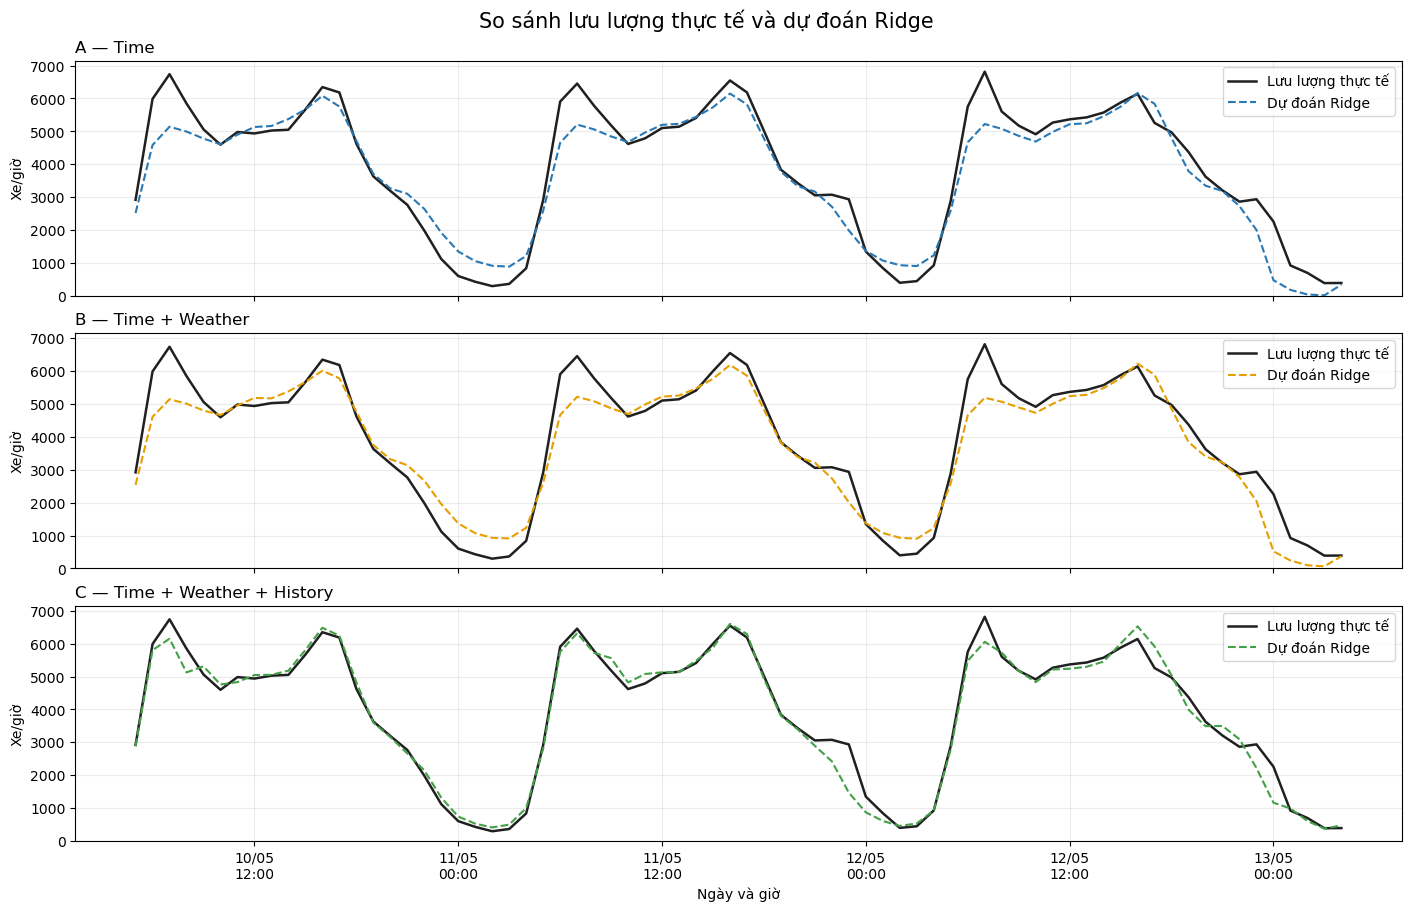

In [22]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Có thể thay thời điểm bắt đầu và số giờ muốn xem.
start_time = prediction_table_common["date_time"].min()
hours_to_plot = 72

# Tạo lưới giờ cho riêng phần vẽ.
# Những giờ thiếu giữ NaN để đường biểu diễn ngắt tại khoảng trống.
plot_index = pd.date_range(
    start=start_time,
    periods=hours_to_plot,
    freq="h",
)
plot_data = (
    prediction_table_common
    .set_index("date_time")
    .sort_index()
    .reindex(plot_index)
)

plot_configs = [
    ("A — Time", "du_doan_A", "#2878B5"),
    ("B — Time + Weather", "du_doan_B", "#E69F00"),
    ("C — Time + Weather + History", "du_doan_C", "#43A047"),
]

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 9),
    sharex=True,
    sharey=True,
    layout="constrained",
)

for ax, (title, prediction_column, color) in zip(axes, plot_configs):
    ax.plot(
        plot_data.index,
        plot_data["traffic_volume"],
        color="#202020",
        linewidth=1.8,
        label="Lưu lượng thực tế",
    )
    ax.plot(
        plot_data.index,
        plot_data[prediction_column],
        color=color,
        linewidth=1.5,
        linestyle="--",
        label="Dự đoán Ridge",
    )

    ax.set_title(title, loc="left")
    ax.set_ylabel("Xe/giờ")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")

axes[-1].xaxis.set_major_locator(
    mdates.HourLocator(byhour=[0, 12])
)
axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%d/%m\n%H:%M")
)
axes[-1].set_xlabel("Ngày và giờ")

fig.suptitle(
    "So sánh lưu lượng thực tế và dự đoán Ridge",
    fontsize=15,
)
plt.show()

### Baseline trung bình theo thứ và giờ

Dự đoán bằng trung bình traffic_volume của cùng cặp day_of_week và hour
trong train_common. Nếu không có nhóm tương ứng, dùng trung bình toàn
train_common làm giá trị dự phòng.

Đánh giá trên cùng validation_common với Ridge A/B/C và bổ sung đường
dự đoán baseline vào các biểu đồ so sánh.

In [23]:
# Chỉ tính trung bình từ train chung.
mean_by_weekday_hour = (
    train_common
    .groupby(["day_of_week", "hour"])["traffic_volume"]
    .mean()
)
global_train_mean = train_common["traffic_volume"].mean()

# Tra trung bình tương ứng với thứ và giờ của từng dòng validation.
validation_keys = pd.MultiIndex.from_frame(
    validation_common[["day_of_week", "hour"]]
)
mean_lookup = mean_by_weekday_hour.reindex(validation_keys)

fallback_count = int(mean_lookup.isna().sum())
prediction_mean = mean_lookup.fillna(global_train_mean).to_numpy()

assert len(prediction_mean) == len(validation_common)
assert np.isfinite(prediction_mean).all()
assert (prediction_mean >= 0).all()

print("Số nhóm thứ–giờ học được:", len(mean_by_weekday_hour))
print("Trung bình toàn train dự phòng:", round(global_train_mean, 3))
print("Số giờ cần dùng giá trị dự phòng:", fallback_count)

print("Ví dụ các giá trị trung bình đã học:")
display(
    mean_by_weekday_hour
    .rename("trung_binh_luu_luong")
    .reset_index()
    .head(10)
)

# Tính độ đo trên đúng các giờ validation dùng cho Ridge A/B/C.
mean_result = pd.DataFrame([{
    "cau_hinh": "Trung bình thứ–giờ",
    "so_train": len(train_common),
    "so_validation": len(validation_common),
    "MAE": mean_absolute_error(y_validation_common, prediction_mean),
    "RMSE": root_mean_squared_error(y_validation_common, prediction_mean),
    "R2": r2_score(y_validation_common, prediction_mean),
}])

comparison_with_mean = pd.concat(
    [
        mean_result,
        comparison_common[
            ["cau_hinh", "so_train", "so_validation", "MAE", "RMSE", "R2"]
        ],
    ],
    ignore_index=True,
)

print("So sánh baseline và Ridge trên cùng dữ liệu:")
display(comparison_with_mean)

# Bổ sung dự đoán baseline vào bảng phục vụ vẽ hình.
prediction_table_with_mean = prediction_table_common.copy()

assert prediction_table_with_mean["date_time"].equals(
    validation_common["date_time"]
)

prediction_table_with_mean["du_doan_trung_binh"] = prediction_mean

Số nhóm thứ–giờ học được: 168
Trung bình toàn train dự phòng: 3232.853
Số giờ cần dùng giá trị dự phòng: 0
Ví dụ các giá trị trung bình đã học:


,day_of_week,hour,trung_binh_luu_luong
0,0,0,636.570370
1,0,1,380.376812
2,0,2,290.525547
3,0,3,338.485507
4,0,4,789.078014
5,0,5,2534.957746
6,0,6,5157.679104
7,0,7,5811.492537
8,0,8,5229.671642
9,0,9,4515.360656


So sánh baseline và Ridge trên cùng dữ liệu:


,cau_hinh,so_train,so_validation,MAE,RMSE,R2
0,Trung bình thứ–giờ,22503,6050,291.738825,503.218512,0.934378
1,A — Time,22503,6050,563.855643,759.875048,0.850369
2,B — Time + Weather,22503,6050,565.035014,760.505513,0.850121
3,C — Time + Weather + History,22503,6050,328.654823,514.053776,0.931522


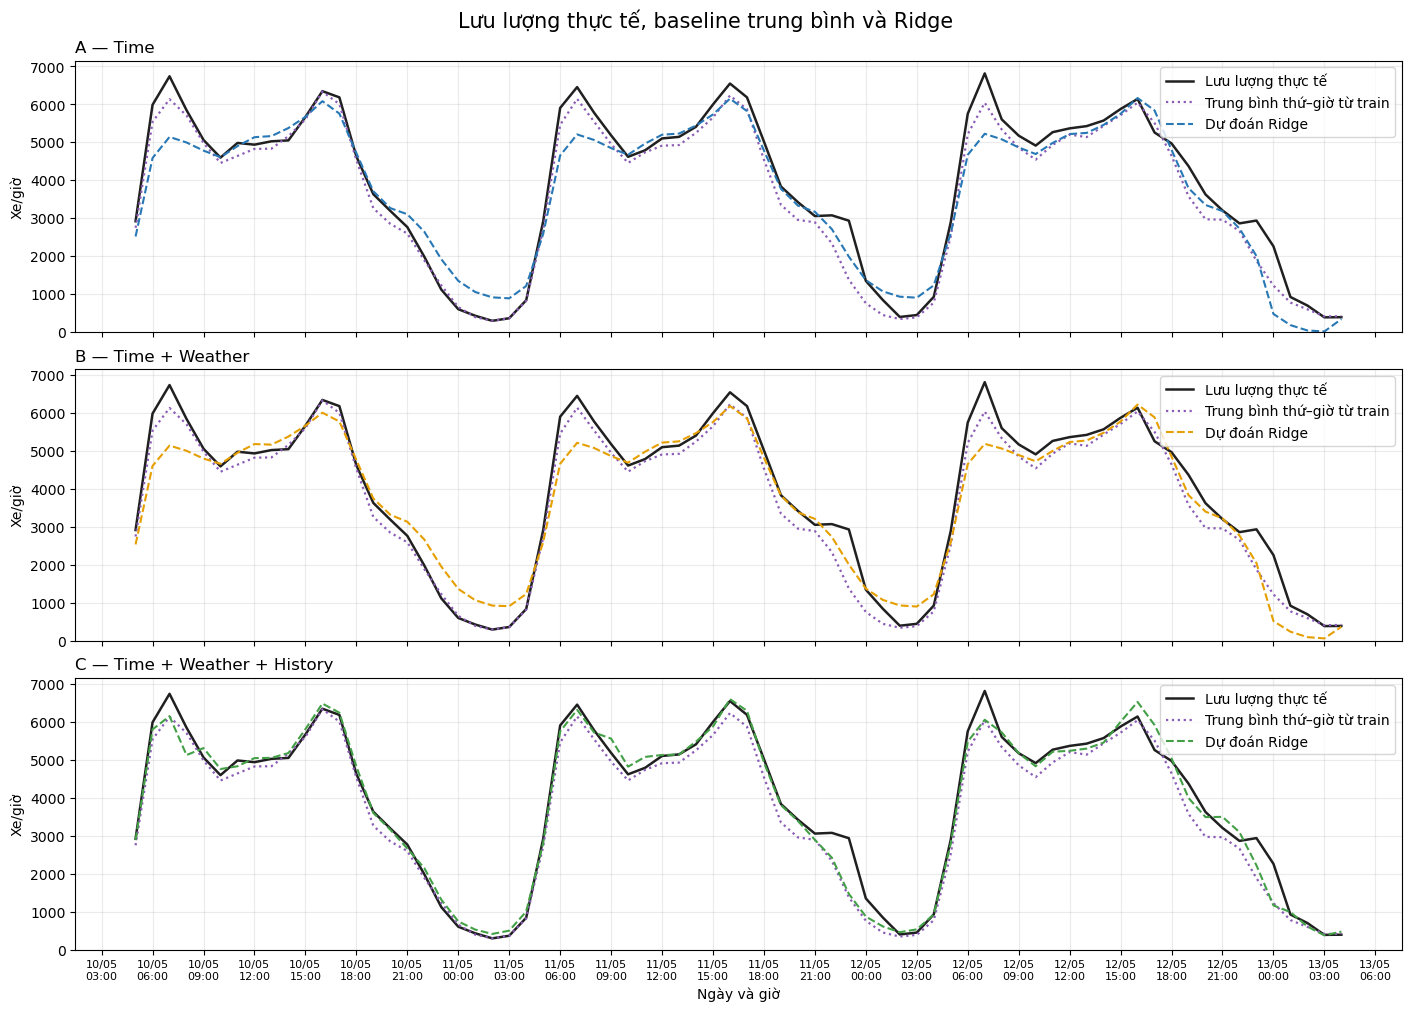

In [26]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

start_time = prediction_table_with_mean["date_time"].min()
hours_to_plot = 72

# Các khoảng thiếu được để NaN để đường vẽ ngắt tại đó.
plot_index = pd.date_range(
    start=start_time,
    periods=hours_to_plot,
    freq="h",
)
plot_data = (
    prediction_table_with_mean
    .set_index("date_time")
    .sort_index()
    .reindex(plot_index)
)

plot_configs = [
    ("A — Time", "du_doan_A", "#2878B5"),
    ("B — Time + Weather", "du_doan_B", "#E69F00"),
    ("C — Time + Weather + History", "du_doan_C", "#43A047"),
]

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 10),
    sharex=True,
    sharey=True,
    layout="constrained",
)

for ax, (title, prediction_column, color) in zip(axes, plot_configs):
    ax.plot(
        plot_data.index,
        plot_data["traffic_volume"],
        color="#202020",
        linewidth=1.8,
        label="Lưu lượng thực tế",
    )
    ax.plot(
        plot_data.index,
        plot_data["du_doan_trung_binh"],
        color="#8A5CB6",
        linewidth=1.6,
        linestyle=":",
        label="Trung bình thứ–giờ từ train",
    )
    ax.plot(
        plot_data.index,
        plot_data[prediction_column],
        color=color,
        linewidth=1.5,
        linestyle="--",
        label="Dự đoán Ridge",
    )

    ax.set_title(title, loc="left")
    ax.set_ylabel("Xe/giờ")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")

# Hiển thị mốc lúc 00:00, 03:00, 06:00, ..., 21:00.
axes[-1].xaxis.set_major_locator(
    mdates.HourLocator(byhour=range(0, 24, 3))
)
axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%d/%m\n%H:%M")
)
axes[-1].tick_params(axis="x", labelsize=8)
axes[-1].set_xlabel("Ngày và giờ")

fig.suptitle(
    "Lưu lượng thực tế, baseline trung bình và Ridge",
    fontsize=15,
)
plt.show()